In [2]:
import pandas as pd

 Import two datasetscomments_file_path = 'UdemyComments.csv'
course_info_file_path = 'Course_info.csv'

output_file_path = 'Merged_UdemyData.csv'

# Load the datasets
comments_df = pd.read_csv(comments_file_path)
course_info_df = pd.read_csv(course_info_file_path)

merged_df = pd.merge(comments_df, course_info_df, left_on='course_id', right_on='id')


merged_df.to_csv(output_file_path, index=False)

print(f'Successfully saved the merged dataset to {output_file_path}')


Successfully saved the merged dataset to Merged_UdemyData.csv


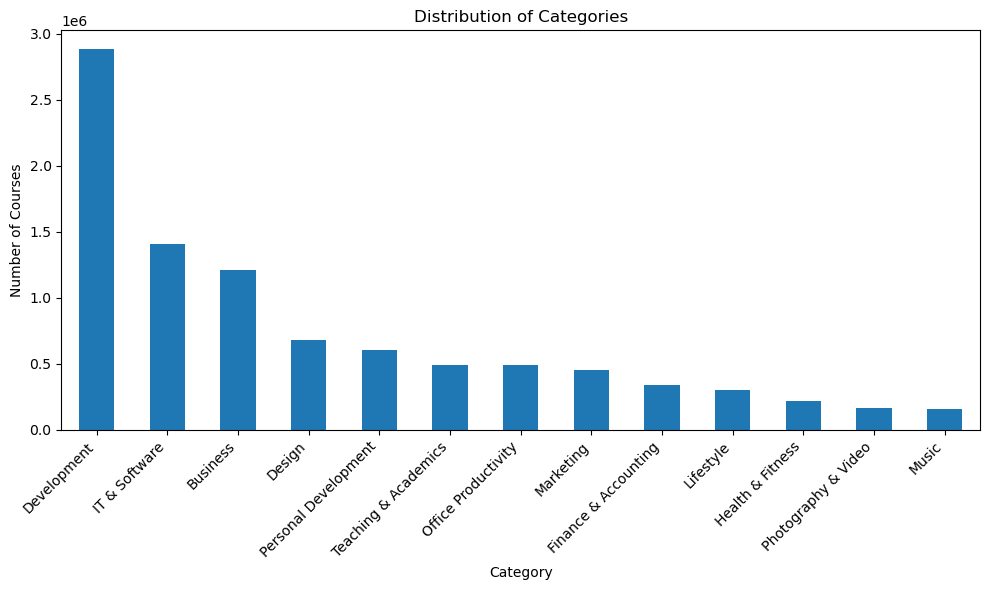

In [3]:
import pandas as pd
import matplotlib.pyplot as plt


merged_file_path = 'Merged_UdemyData.csv'


df = pd.read_csv(merged_file_path)


category_counts = df['category'].value_counts()


plt.figure(figsize=(10, 6))
category_counts.plot(kind='bar')
plt.title('Distribution of Categories')
plt.xlabel('Category')
plt.ylabel('Number of Courses')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()


plt.show()


In [4]:
import pandas as pd
from langdetect import detect
from langdetect.lang_detect_exception import LangDetectException
from tqdm import tqdm


merged_file_path = 'Merged_UdemyData.csv'


filtered_file_path = 'UdemyComments_EnglishOnly.csv'

df = pd.read_csv(merged_file_path,nrows=3000000)


def is_english(comment):
    try:

        comment = str(comment)
        return detect(comment) == 'en'
    except LangDetectException:
        return False


df['comment'] = df['comment'].astype(str)


tqdm.pandas()


df['is_english'] = df['comment'].progress_apply(is_english)
df_english = df[df['is_english']]


df_english = df_english.drop(columns=['is_english'])


df_english.to_csv(filtered_file_path, index=False)

print(f'Successfully saved the filtered dataset with English comments to {filtered_file_path}')


100%|██████████████████████████████| 3000000/3000000 [1:18:55<00:00, 633.51it/s]


Successfully saved the filtered dataset with English comments to UdemyComments_EnglishOnly.csv


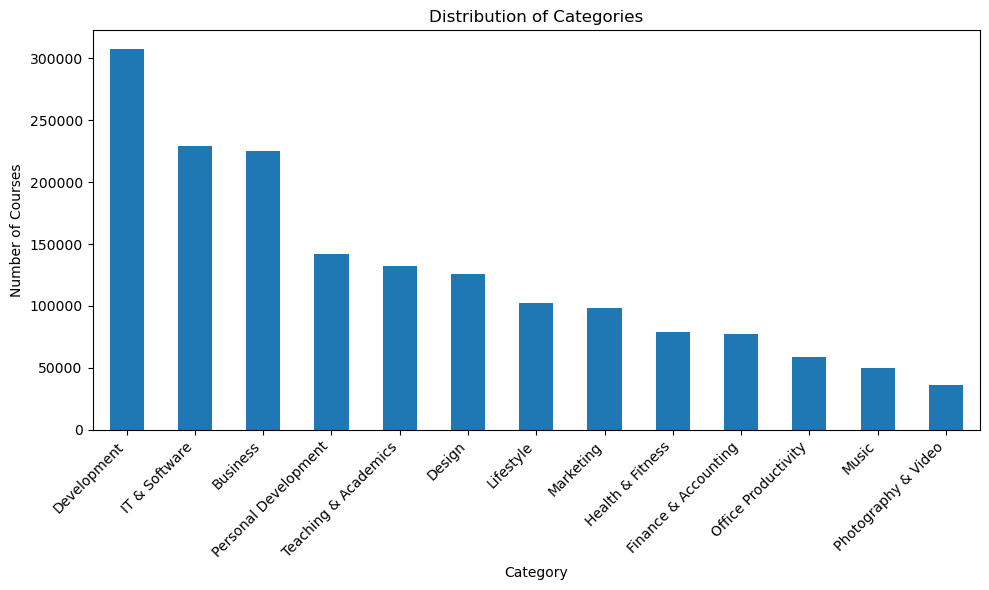

In [5]:
import pandas as pd
import matplotlib.pyplot as plt


merged_file_path = 'UdemyComments_EnglishOnly.csv'


df = pd.read_csv(merged_file_path)


category_counts = df['category'].value_counts()


plt.figure(figsize=(10, 6))
category_counts.plot(kind='bar')
plt.title('Distribution of Categories')
plt.xlabel('Category')
plt.ylabel('Number of Courses')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()



plt.show()


In [5]:
import pandas as pd


file_path = 'UdemyComments_EnglishOnly.csv'
df = pd.read_csv(file_path)


grouping_strategy = {
    'Personal Development and Lifestyle': ['Personal Development', 'Lifestyle'],
    'Technology and IT': ['Development', 'IT & Software'],
    'Business and Finance': ['Business', 'Finance & Accounting'],
    'Education and Teaching': ['Teaching & Academics'],
    'Health and Fitness': ['Health & Fitness'],
    'Creative and Design': ['Design', 'Photography & Video', 'Music'],
    'Marketing and Productivity': ['Marketing', 'Office Productivity']
}


category_to_group = {}
for group, categories in grouping_strategy.items():
    for category in categories:
        category_to_group[category] = group


df['group_category'] = df['category'].map(category_to_group)

df_grouped = df.dropna(subset=['group_category'])


df_grouped = df_grouped[['group_category', 'comment','id_x','rate']]


output_file_path = 'Udemy_grouped_by_category.csv'
df_grouped.to_csv(output_file_path, index=False)


print(f"Grouped dataset has been saved to {output_file_path}")


Grouped dataset has been saved to Udemy_grouped_by_category.csv


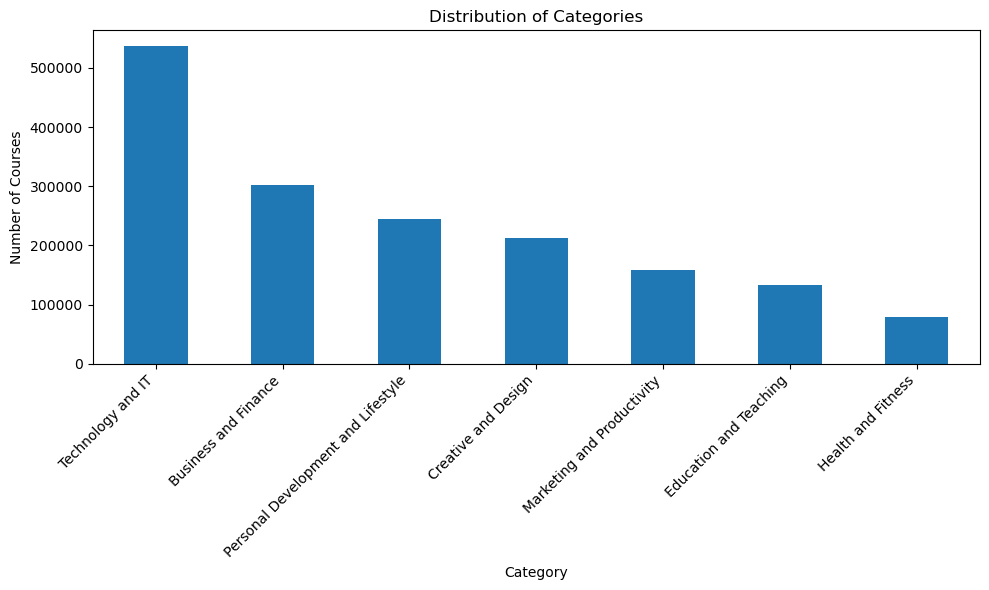

In [6]:
import matplotlib.pyplot as plt
category_counts = df_grouped['group_category'].value_counts()


plt.figure(figsize=(10, 6))
category_counts.plot(kind='bar')
plt.title('Distribution of Categories')
plt.xlabel('Category')
plt.ylabel('Number of Courses')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()



plt.show()
